#1.0 Dataset 1 - Digital Insomnia: The Bedtime Screen Penalty

In [ ]:
import kagglehub
path = kagglehub.dataset_download("beamhonor0911/digital-insomnia-screen-habits-sleep")

Using Colab cache for faster access to the 'digital-insomnia-screen-habits-sleep' dataset.


##1. Importação das Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, f1_score, recall_score



In [ ]:
# Importando o Dataset do Kaggle
df1 = pd.read_csv(os.path.join(path, "sleep_debt_screen_time.csv"))





Mostrando

In [ ]:
print(df1.shape)
df1.head()

(8500, 23)


,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


##2. Análise Exploratória de Dados

primeiro olhar os tipos das colunas, ver se tem nulos e linhas repetidas

In [ ]:
print("Valores nulos por colunas", df1.isna().sum())

print("Valores duplicados: ", df1.duplicated().sum())

df1.describe().T

Valores nulos por colunas user_id                       0
age                           0
gender                        0
chronotype                    0
occupation                    0
bedtime_hour                  0
screen_time_before_bed_min    0
primary_app_category          0
screen_brightness_pct         0
blue_light_filter_on          0
caffeine_intake_mg            0
caffeine_last_hour            0
physical_activity_min         0
room_temperature_f            0
ambient_noise_db              0
sleep_onset_latency_min       0
total_sleep_hours             0
rem_sleep_pct                 0
deep_sleep_pct                0
awakenings_count              0
sleep_efficiency_pct          0
next_day_fatigue_score        0
sleep_debt_category           0
dtype: int64
Valores duplicados:  0


,count,mean,std,min,25%,50%,75%,max
user_id,8500.0,4250.500000,2453.882977,1.00,2125.75,4250.50,6375.25,8500.00
age,8500.0,28.099647,9.007551,16.00,21.00,27.00,34.00,65.00
bedtime_hour,8500.0,13.883186,10.836579,0.00,1.09,22.20,23.15,24.00
screen_time_before_bed_min,8500.0,53.744118,35.349292,5.00,29.00,45.00,68.00,240.00
screen_brightness_pct,8500.0,68.770235,18.923090,5.00,56.00,69.00,83.00,100.00
caffeine_intake_mg,8500.0,79.650000,78.348824,0.00,22.00,55.50,113.00,500.00
caffeine_last_hour,8500.0,15.905871,3.844196,6.00,13.20,16.00,18.70,23.00
physical_activity_min,8500.0,29.761882,30.000228,0.00,8.00,20.00,42.00,180.00
room_temperature_f,8500.0,70.083506,3.962443,58.00,67.40,70.10,72.70,82.00
ambient_noise_db,8500.0,34.972753,10.011726,10.00,28.20,35.00,41.50,70.00


Nao tem nulo e nem valores duplicados

In [ ]:


colunas_para_remover = [
    'blue_light_filter_on',
    'primary_app_category',
    'occupation',
    'chronotype',
    'gender',
]

df1 = df1.drop(columns=colunas_para_remover, errors='ignore')
df1.head()

,user_id,age,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,23.94,102,100,264,21.5,73,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,0.06,14,87,18,12.6,25,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,1.48,58,76,62,16.5,48,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,22.42,48,56,42,18.9,9,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,22.43,29,96,78,16.3,5,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


##3. Divisão dos Dados

count       4.000000
mean     2125.000000
std      1804.876358
min        25.000000
25%      1297.000000
50%      2041.000000
75%      2869.000000
max      4393.000000
Name: count, dtype: float64


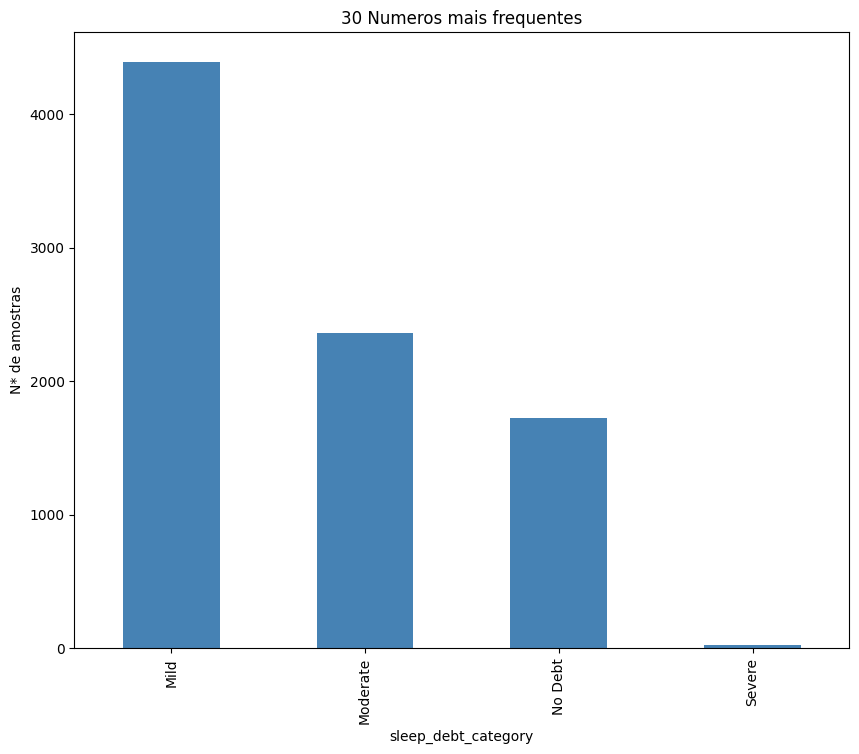

In [ ]:
#contando quantos minutos cada pessoa fica
cont = df1['sleep_debt_category'].value_counts()

print(cont.describe())

#Grafico de 30 valores que mais aparecem de minutos

plt.figure(figsize=(10,8));
cont.head(30).plot(kind='bar', color='steelblue')
plt.title("30 Numeros mais frequentes");
plt.ylabel("N* de amostras");
plt.tight_layout;
plt.show()





In [ ]:


x = df1.drop("sleep_debt_category", axis=1)
y = df1['sleep_debt_category']

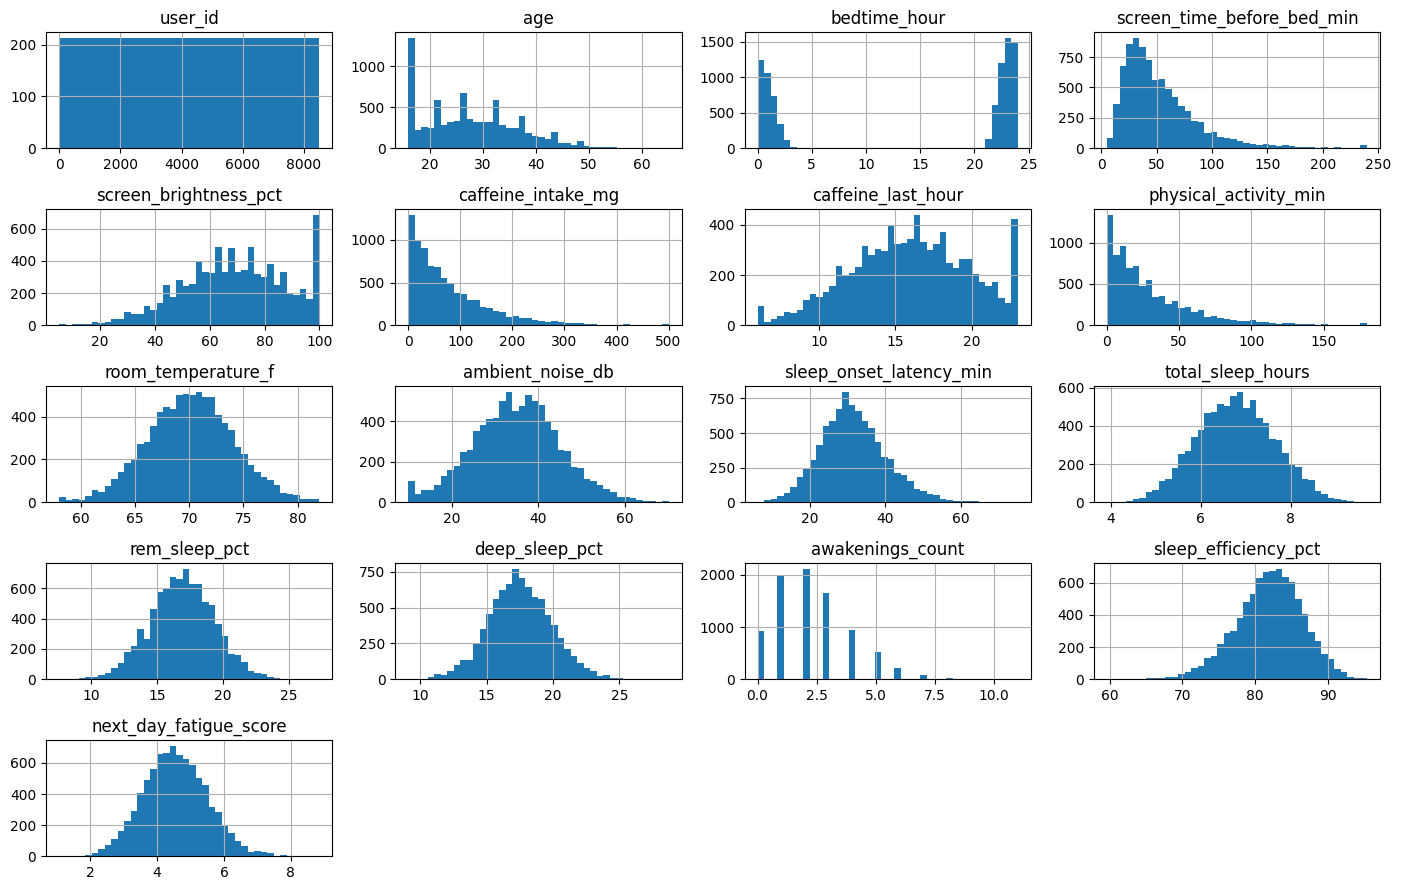

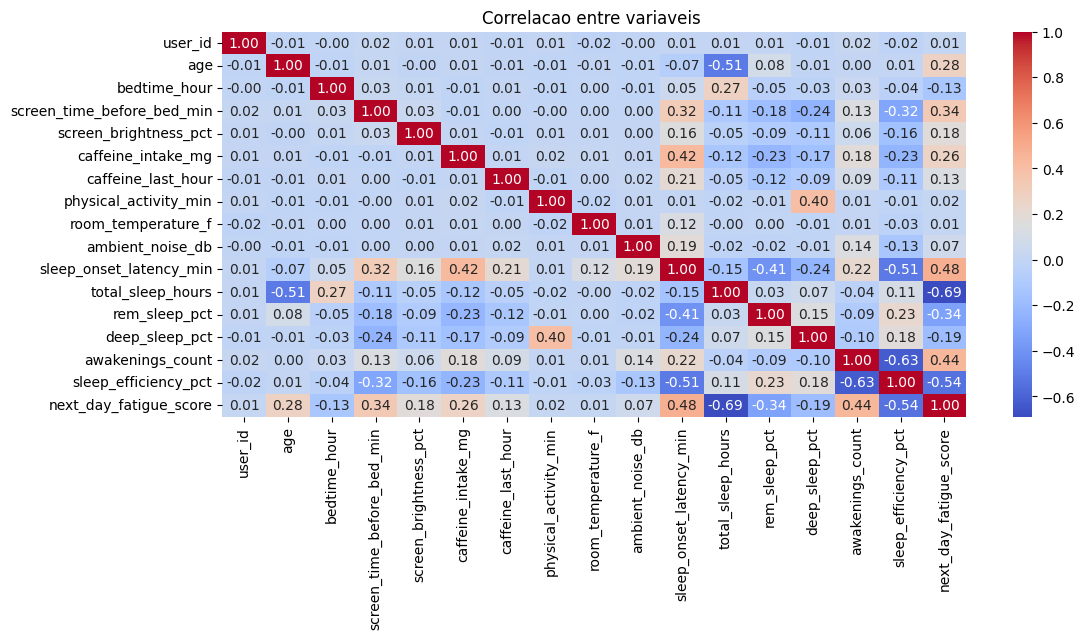

In [ ]:
#Histograma de cada variavel

feats = [c for c in x.columns if c!= 'sleep_debt_category']

x.hist(bins=40, figsize=(14,9));
plt.tight_layout();
plt.show()

#correlacao entre as variaveis
plt.figure(figsize=(12,5));
sns.heatmap(x.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlacao entre variaveis ");
plt.show()



In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

print("Treino: ", x_train.shape)
print("Teste: ", x_test.shape)

Treino:  (6800, 17)
Teste:  (1700, 17)


 Treinamento do Treino e Teste

## Treinamento

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Cria uma variável para os modelos já treinados
modelos_treinados = {}

# Loop para treinar cada modelo e adicioná-los aos modelos treinados
for nome, modelo in modelos.items():
  modelo.fit(x_train, y_train)
  modelos_treinados[nome] = modelo
  print(f'Treinamento do modelo {nome} concluído')

Treinamento do modelo Árvore de Decisão concluído
Treinamento do modelo Random Forest concluído
Treinamento do modelo Gradient Boosting concluído


In [ ]:
#Validacao Cruzada

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])


#validacao Cruzada com 5 folds

cv = KFold(n_splits=5, shuffle=True, random_state=42)
base = cross_val_score(pipe, x_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)

print("CV 5-fold, SVC-padrao: ", base.round(4))
print("media: ", base.mean())
print("Desvio Padrao: ", base.std())

CV 5-fold, SVC-padrao:  [0.7971 0.8125 0.8029 0.8257 0.8235]
media:  0.8123529411764705
Desvio Padrao:  0.011193871902344115


Grid Search

In [ ]:
param_grid = {
    'svm__kernel': ['linear', 'rbf', 'poly','sigmoid'],
    'svm__C': [0.1,1,10,100],
    'svm__gamma': [0.001,0.01,0.1,1],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
grid.fit(x_train,y_train)

print("Melhores parametros: ", grid.best_params_)
print("Melhor Acuracia Score na validacao cruzada: ",  grid.best_score_)



Fitting 5 folds for each of 64 candidates, totalling 320 fits


In [ ]:
# tabela com as 10 melhores combinacoes

res = pd.DataFrame(grid.cv_results_)[['param_svm__kernel','param_svm__C','param_svm__gamma','mean_test_score','std_test_score']]
res.sort_values('mean_test_score', ascending=False).head(10)

In [ ]:
#um heatmap por kernel pra comparar C x gamma
fig, axes = plt.subplots(1,4, figsize=(20,4))
for ax, k in zip(axes, param_grid['svm__kernel']):
  t = res[res.param_svm__kernel==k].pivot_table(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')
  sns.heatmap(t, annot=True, fmt='.3f', cmap='viridis', ax=ax, vmin=0, vmax=1);
  ax.set_title(f'kernel = {k}')
  plt.tight_layout();
  plt.show()

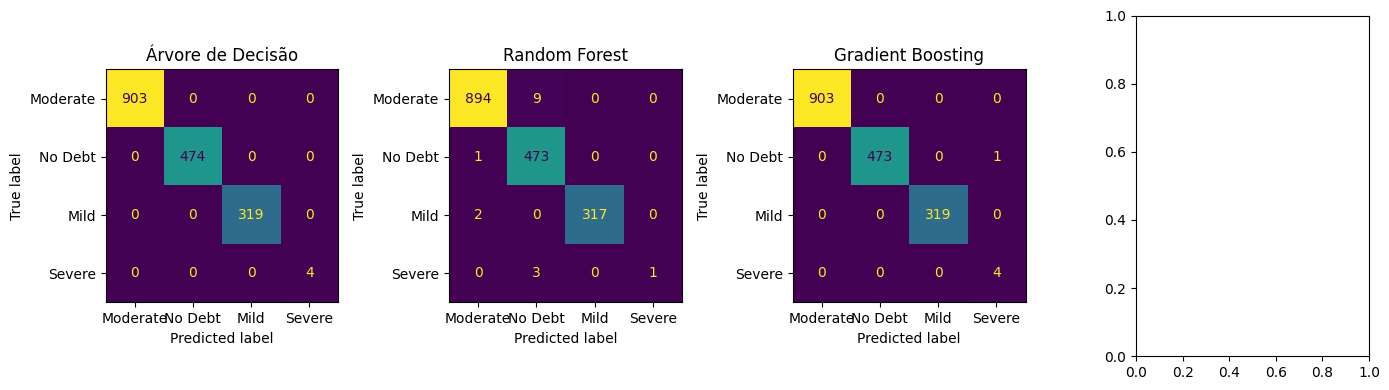

In [ ]:
# Cria as matrizes de confusão dos resultados das predições dos modelos
fig, axes = plt.subplots(1,4, figsize=(14,4))

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
  ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=y.unique(), ax=ax, colorbar=False)
  ax.set_title(nome)

plt.tight_layout()
plt.show()

1.6 Modelo final: acuracia e matrix de confusao

In [ ]:
modelo = grid.best_estimator_
y_pred = modelo.predict(x_test)

print('Modelo: ', modelo.named_steps['svm'])
print('Acuracia no teste: %.4f' % accuracy_score(y_test, y_pred))

# precisao, recall e f1
print(classification_report(y_test,y_pred, zero_division=0))

In [ ]:
#matrix de confusao

fig, ax = plt.subplots(figsize=(12,10))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=modelo.classes_), display_labels=modelo.classes_).plot(ax=ax, xticks_rotation=90, cmap='Blues', colorbar=False)
plt.title("Matrix de Confusao - SVM (teste)")
plt.tight_layout()
plt.show()

##5. Teste

In [ ]:

# Realiza as predições com os modelos treinados
previsoes = {nome: modelo.predict(x_test) for nome, modelo in modelos_treinados.items()}

for nome, y_pred in previsoes.items():
  print(f'{nome} -- {y_pred}')

##6. Teste e Comparação

In [ ]:

resultados = []

# Realiza um teste de acurácia e gera um relatório de classificação com cada modelo treinado
for nome, y_pred in previsoes.items():
  acuracia = accuracy_score(y_test, y_pred)
  resultados.append({'Modelo': nome, 'Acurácia': acuracia})
  print(f'{nome} -- Acurácia: {acuracia:.2f}')
  print(classification_report(y_test, y_pred))

In [ ]:

print('Modelo : SVC ')
print('Kernel : ', grid.best_params_['svm__kernel'])
print('C : ', grid.best_params_['svm__C'])
print('gamma : ', grid.best_params_['svm__gamma'])
print('Acuracia CV : %.4f' % grid.best_score_)
print("Acuracia no teste : %.4f" % accuracy_score(y_test, y_pred))

# 2.0 Segundo Dataset : FISHMORPH – Classificação de Famílias de Peixes com SVM




##1. Impotação das Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, f1_score, recall_score

In [ ]:
# Importando o dataset do kaggle

import kagglehub
path = kagglehub.dataset_download("menegidio/fishmorph-dataset")

In [ ]:
#Lendo o CSV
df2 = pd.read_csv(os.path.join(path, "FISHMORPH_Family_Dataset.csv"))



In [ ]:
print(df2.shape)

df2.head()

##2. Análise Exploratória de Dados

In [ ]:
df2.info()

print("Nulos por coluna: ", dataset2.isna().sum())
print()

print("Duplicados por linha: ", dataset2.duplicated().sum())
print()

dataset2.describe().T

Percebemos que nao tem nenhum nulo, mas tem uma linha que esta duplicada.


In [ ]:
df2 = dataset2.dropna().drop_duplicates().reset_index(drop=True)
print("Mostrando o shape: ", dataset2.shape)
print()
print("Quantidade de Familias: ", dataset2['Family'].nunique())

##3. Divisão dos Dados

In [ ]:
cont=df2['Family'].value_counts()
print(cont.describe())

In [ ]:
#grafico com as familias que mais aparecem

plt.figure(figsize=(10,5))
cont.head(30).plot(kind='bar', color='blue')
plt.title("Familias que mais aparecem")
plt.ylabel("Numero de amostras")
plt.tight_layout()
plt.show()

In [ ]:
df2 = df2.copy()

x = df2.drop("Family", axis=1)
y = df2['Family']

In [ ]:
#Histograma de cada variavel

feats = [c for c in x.columns if c!= 'Family']

x.hist(bins=40, figsize=(14,9));
plt.tight_layout();
plt.show()

#correlacao entre as variaveis
plt.figure(figsize=(12,5));
sns.heatmap(x.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlacao entre variaveis ");
plt.show()

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

print("Treino: ", x_train.shape)
print("Teste: ", x_test.shape)

##4. Treinamento

In [ ]:
modelos = {
    'Arvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Cria uma variável para os modelos já treinados
modelos_treinados = {}

# Loop para treinar cada modelo e adicioná-los aos modelos treinados
for nome, modelo in modelos.items():
  modelo.fit(x_train, y_train)
  modelos_treinados[nome] = modelo
  print(f'Treinamento do modelo {nome} concluído')

In [ ]:
#Validacao Cruzada

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])


#validacao Cruzada com 5 folds

cv = KFold(n_splits=5, shuffle=True, random_state=42)
base = cross_val_score(pipe, x_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)

print("CV 5-fold, SVC-padrao: ", base.round(4))
print("media: ", base.mean())
print("Desvio Padrao: ", base.std())

GridSearch

In [ ]:
param_grid = {
    'svm__kernel': ['linear', 'rbf', 'poly','sigmoid'],
    'svm__C': [0.1,1,10,100],
    'svm__gamma': [0.001,0.01,0.1,1],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
grid.fit(x_train,y_train)

print("Melhores parametros: ", grid.best_params_)
print("Melhor Acuracia Score na validacao cruzada: ",  grid.best_score_)



In [ ]:
# tabela com as 10 melhores combinacoes

res = pd.DataFrame(grid.cv_results_)[['param_svm__kernel','param_svm__C','param_svm__gamma','mean_test_score','std_test_score']]
res.sort_values('mean_test_score', ascending=False).head(10)

In [ ]:
#um heatmap por kernel pra comparar C x gamma
fig, axes = plt.subplots(1,4, figsize=(20,4))
for ax, k in zip(axes, param_grid['svm__kernel']):
  t = res[res.param_svm__kernel==k].pivot_table(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')
  sns.heatmap(t, annot=True, fmt='.3f', cmap='viridis', ax=ax, vmin=0, vmax=1);
  ax.set_title(f'kernel = {k}')
  plt.tight_layout();
  plt.show()

In [ ]:
# Cria as matrizes de confusão dos resultados das predições dos modelos
fig, axes = plt.subplots(1,4, figsize=(14,4))

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
  ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=y.unique(), ax=ax, colorbar=False)
  ax.set_title(nome)

plt.tight_layout()
plt.show()

In [ ]:
previsoes = {nome: modelo.predict(x_test) for nome, modelo in modelos_treinados.items()}

print(f'Valores reais: {y_test}')

for nome, y_pred in previsoes.items():
  print(f'{nome}: {y_pred}')

##5. Teste

In [ ]:
modelo = grid.best_estimator_
y_pred = modelo.predict(x_test)

print('Modelo: ', modelo.named_steps['svm'])
print('Acuracia no teste: %.4f' % accuracy_score(y_test, y_pred))

# precisao, recall e f1
print(classification_report(y_test,y_pred, zero_division=0))

Resumo Final

##6. Avaliação e Comparação

In [ ]:

resultados = []

# Realiza um teste de acurácia e gera um relatório de classificação com cada modelo treinado
for nome, y_pred in previsoes.items():
  acuracia = accuracy_score(y_test, y_pred)
  resultados.append({'Modelo': nome, 'Acurácia': acuracia})
  print(f'{nome} -- Acurácia: {acuracia:.2f}')
  print(classification_report(y_test, y_pred))

In [ ]:
print('-------- Resumo --------')
print('Modelo : SVC ')
print('Kernel : ', grid.best_params_['svm__kernel'])
print('C : ', grid.best_params_['svm__C'])
print('gamma : ', grid.best_params_['svm__gamma'])
print('Acuracia CV : %.4f' % grid.best_score_)
print("Acuracia no teste : %.4f" % accuracy_score(y_test, y_pred))

In [ ]:
#matrix de confusao

fig, axes = plt.subplots(1, 4, figsize=(14,4))

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
  ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=y.unique(), ax=ax, colorbar=False)
  ax.set_title(nome)

plt.tight_layout()
plt.show()

# 3.0 Terceiro Dataset : LitDigestFull

##1. Importação das Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, f1_score, recall_score

In [ ]:
df = pd.read_excel("LitDigestFull.xlsx", sheet_name=None) # Definindo o DataFrame como o arquivo lido em .xlsx

# Tira os limites de exibição do pandas para exibir os DataFrames por inteiro
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

Definindo os Dataframes 1924, 1928, 1932 e 1936

In [ ]:
df_1924 = df['1924'] # Define o DataFrame de 1924 como a página de 1924 presente no arquivo

df_1924

In [ ]:
df_1928 = df['1928'] # Define o DataFrame de 1928 como a página de 1928 presente no arquivo

df_1928

In [ ]:
df_1932 = df['1932'] # Define o DataFrame de 1932 como a página de 19232 presente no arquivo

df_1932

In [ ]:
df_1936 = df['1936'] # Define o DataFrame de 1936 como a página de 1936 presente no arquivo


df_1936

##2. Análise Exploratória de Dados

###Dataframe 1924

In [ ]:
df_1924.shape # Mostra o formato do DataFrame (Linhas, Colunas)

In [ ]:
df_1924.isna().sum() # Mostra se há valores nulos no DataFrame

In [ ]:
df_1924.duplicated().sum() # Mostra se há valores duplicados

In [ ]:
df_1924.info()

In [ ]:
df_1924.describe()

In [ ]:
# Deleta as colunas que não oferecem valor preditivo
df_1924 = df_1924.drop(columns=['Unnamed: 11', 'Unnamed: 20', 'https://en.wikipedia.org/wiki/1924_United_States_presidential_election', 'Electoral votes.3', 'Electoral votes.4', 'Electoral votes.5', 'Electoral votes.6'])

df_1924 = df_1924.rename(columns={
    'Unnamed: 44': 'State'
})

df_1924['ELECTORAL VOTE'] = df_1924['ELECTORAL VOTE'].fillna(0) # Preenche os valores nulos da coluna 'ELECTORAL VOTE' com 0

df_1924.head()

In [ ]:
# Troca o valor da última linha por Totals
df_1924.loc[df_1924.index[50], '1924 VOTE'] = 'TOTALS:'
df_1924.loc[df_1924.index[50], 'HOW THE SAME VOTERS VOTED IN 1920'] = 'TOTALS:'

In [ ]:
# Divide parte do DataFrame
df_pesquisa = df_1924.iloc[:, :19]
df_pesquisa.head()

In [ ]:
df_eleicao = df_1924.iloc[:, 19:]
df_eleicao.head()

In [ ]:
df_eleicao = df_eleicao.rename(columns={
    'State - 1924': '1924 VOTE'
})

df_1924 = pd.merge(df_pesquisa, df_eleicao, on='1924 VOTE') # Junta os dois DataFrames criados

df_1924.head()

In [ ]:
df_1924.isna().sum()

In [ ]:
df_1924 = df_1924.replace('-', 0)

In [ ]:
lista_partidos = []

# Cria um loop para verificar cada valor presente nas colunas dos candidatos, verificando qual teve o valor mais alto em cada linha e os guardando em uma lista
for i in range(0, 48):
  republicanos = df_1924.loc[df_1924.index[i], 'Coolidge']
  democratas = df_1924.loc[df_1924.index[i], 'Davis']
  progressistas = df_1924.loc[df_1924.index[i], 'LaFollette (Prog)']

  partidos = np.array([republicanos, democratas, progressistas])

  vencedor = partidos.max()

  if vencedor == republicanos:
    partido_vencedor = 'Rep'
  else:
    partido_vencedor = 'Dem'

  lista_partidos.append(partido_vencedor)

df_1924['Winner Party'] = lista_partidos # Cria uma nova coluna com os vencedores em cada Estado

df_1924

In [ ]:
novos_nomes = {
    '1924 VOTE': 'State',
    'COOLIDGE': 'Votes Rep.',
    'DAVIS': 'Votes Dem.',
    'LA FOLLETTE': 'Votes Others',
    'REP.': 'Hist. Rep.',
    'DEM.': 'Hist. Dem.',
    'SOC.': 'Hist. Others',
    'DID NOT VOTE': 'Hist. No Vote',
    'Coolidge': 'Real Votes Rep.',
    '%': '% Rep.',
    'Davis': 'Real Votes Dem.',
    '%.1': '% Dem.',
    'LaFollette (Prog)': 'Real Votes Others',
    '%.2': '% Others',
    '%.6': '% Margin',
    'TOTAL': 'Total',
    'State': 'State Abbreviation'
}

df_1924.rename(columns=novos_nomes, inplace=True)

df_1924['Votes Others'] = df_1924['Votes Others'] + df_1924['FARIS'] + df_1924['FOSTER'] + df_1924['NATIONS'] + df_1924['WALLACE'] + df_1924['JOHNS']
df_1924['Hist. Others'] = df_1924['Hist. Others'] + df_1924['FARM. LABOR'] + df_1924['PROH.']
df_1924['Real Votes Others'] = df_1924['Real Votes Others'] + df_1924['Faris (Proh.)'] + df_1924['Foster (Comm.)'] + df_1924['Johns (SL)']
df_1924['% Others'] = df_1924['% Others'] + df_1924['%.3'] + df_1924['%.4'] + df_1924['%.5']

df_1924 = df_1924.drop(columns=['FARIS', 'FOSTER', 'NATIONS', 'WALLACE', 'JOHNS', 'FARM. LABOR', 'PROH.', 'Electoral votes.1', 'Electoral votes.2', 'Faris (Proh.)', 'Foster (Comm.)', 'Johns (SL)', '%.3', '%.4', '%.5', 'TOTAL FOR STATE', 'State Abbreviation', 'HOW THE SAME VOTERS VOTED IN 1920'])

df_1924.head()

In [ ]:
df_1924 = df_1924.drop(47)

df_1924

In [ ]:
df_1924.hist(figsize=(20, 16))
plt.tight_layout()
plt.show()

In [ ]:
# Plota um gráfico de barras da distribuição do alvo(target)

df_1924["Winner Party"].value_counts().plot(kind="bar")

plt.xticks(rotation=0)
plt.title("Disposição de candidatos republicanos (Rep) e Democratas (Dem) em 1924")

plt.show()

###Dataframe 1928

In [ ]:
df_1928 # Exibe o DataFrame de 1928

In [ ]:
novos_nomes = {
    'Unnamed: 0': '1928 VOTE',
    'Unnamed: 1': 'ELECTORAL VOTE',
    'How the same voters voted in 1924': 'Rep.',
    'Unnamed: 4': 'Dem.',
    'Unnamed: 5': 'Soc.',
    'Unnamed: 6': 'F.Lab.',
    'Unnamed: 7': 'Proh.',
    'Unnamed: 8': 'No Vote',
    'How the same voters voted in 1924.1': 'Rep.',
    'Unnamed: 12': 'Dem.',
    'Unnamed: 13': 'Soc.',
    'Unnamed: 14': 'F.Lab.',
    'Unnamed: 15': 'Proh.',
    'Unnamed: 16': 'No Vote',
    'Unnamed: 19': 'State',
    'VOTES FOR MINOR CANDIDATES': 'Thomas (Soc.)',
    'Unnamed: 21': 'Foster (Work.)',
    'Unnamed: 22': 'Varney (Proh.)',
    'Unnamed: 23': 'Total'
} # Define novos nomes para as colunas do DataFrame

df_1928.rename(columns=novos_nomes, inplace=True) # Altera o nome das colunas de acordo com os novos nomes definidos

df_1928.head() # Exibe as 5 primeiras linhas do DataFrame

In [ ]:
df_1928 = df_1928.drop(columns=['Unnamed: 9', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 24', 'Unnamed: 46']) # Deletas as colunas que não oferecem valor preditivo

df_1928.head()

In [ ]:
df_1928.shape # Exibe o formato do DataFrame (linhas, colunas)

In [ ]:
df_pesquisa = df_1928.iloc[:, :21]

df_pesquisa.head()

In [ ]:
df_eleicao = df_1928.iloc[:, 21:]

df_eleicao.head()

In [ ]:
df_pesquisa = df_pesquisa.shift(-1) # Sobe as linhas do DataFrame em uma posição

df_pesquisa.head(3)

In [ ]:
df_pesquisa = df_pesquisa.drop(51) # Deleta a última linha do DataFrame

df_pesquisa

In [ ]:
df_eleicao['State - 1928'] = df_eleicao['State - 1928'].str.upper() # Define todos os registros da coluna como letras Maiúsculas
df_eleicao['State - 1928'] = df_eleicao['State - 1928'].str.strip() # Retira espaços em brancos antes e depois das palavras caso hajam

df_pesquisa['1928 VOTE'] = df_pesquisa['1928 VOTE'].str.strip()

df_eleicao = df_eleicao.rename(columns={
    'State - 1928': '1928 VOTE'
})

df_1928 = pd.merge(df_pesquisa, df_eleicao, on='1928 VOTE') # Junta os dois DataFrames criados

df_1928.head()

In [ ]:
df_1928 = df_1928.drop(columns=['Electoral votes.2', 'Electoral votes.3', 'Electoral votes.4', 'Electoral votes.5'])

df_1928.head()

In [ ]:
df_1928 = df_1928.replace('-', 0)

In [ ]:
lista_partidos = []

for i in range(0, 48):
  republicanos = df_1928.loc[df_1928.index[i], 'Hoover']
  democratas = df_1928.loc[df_1928.index[i], 'Smith']

  partidos = np.array([republicanos, democratas])

  vencedor = partidos.max()

  if vencedor == republicanos:
    partido_vencedor = 'Rep'
  elif vencedor == democratas:
    partido_vencedor = 'Dem'

  lista_partidos.append(partido_vencedor)

df_1928['Winner Party'] = lista_partidos

df_1928

In [ ]:
cols = []
count = {}

for col in df_1928.columns:
  if col in count:
    count[col] += 1
    cols.append(f'{col}.{count[col]}')
  else:
    count[col] = 0
    cols.append(col)

df_1928.columns = cols

novos_nomes = {
    '1928 VOTE': 'State',
    'Hoover (R)': 'Votes Rep.',
    'Smith (D)': 'Votes Dem.',
    'Thomas (Soc.)_x': 'Votes Others',
    'Rep.': 'Hist. Rep.',
    'Dem.': 'Hist. Dem.',
    'Soc.': 'Hist. Others',
    'No Vote': 'Hist. No Vote',
    'Hoover': 'Real Votes Rep.',
    '%': '% Rep.',
    'Smith': 'Real Votes Dem.',
    '%.1': '% Dem.',
    'Thomas (Soc.)_y': 'Real Votes Others',
    '%.2': '% Others',
    '%.5': '% Margin',
    'State total': 'State Total'
}

df_1928.rename(columns=novos_nomes, inplace=True)

df_1928['Votes Others'] = df_1928['Votes Others'] + df_1928['Foster (Work.)'] + df_1928['Varney (Proh.)']
df_1928['Hist. Others'] = df_1928['Hist. Others'] + df_1928['F.Lab.'] + df_1928['Proh.'] + df_1928['Soc..1'] + df_1928['F.Lab..1'] + df_1928['Proh..1']
df_1928['Hist. Rep.'] = df_1928['Hist. Rep.'] + df_1928['Rep..1']
df_1928['Hist. Dem.'] = df_1928['Hist. Dem.'] + df_1928['Dem..1']
df_1928['Hist. No Vote'] = df_1928['Hist. No Vote'] + df_1928['No Vote.1']
df_1928['Real Votes Others'] = df_1928['Real Votes Others'] + df_1928['Foster (Comm.)'] + df_1928['Reynolds (Soc. Lab)']
df_1928['% Others'] = df_1928['% Others'] + df_1928['%.3'] + df_1928['%.4']

df_1928 = df_1928.drop(columns=['Foster (Work.)', 'Varney (Proh.)', 'F.Lab.', 'Proh.', 'Rep..1', 'Dem..1', 'Soc..1', 'F.Lab..1', 'Proh..1', '%.3', '%.4', 'No Vote.1', 'Electoral votes.1', 'Foster (Comm.)', 'Reynolds (Soc. Lab)', 'State_x', 'State_y'])

df_1928.head()

In [ ]:
df_1928.hist(figsize=(20, 16))
plt.tight_layout()
plt.show()

In [ ]:
# Plota um gráfico de barras da distribuição do alvo(target)

df_1928["Winner Party"].value_counts().plot(kind="bar")

plt.xticks(rotation=0)
plt.title("Disposição de candidatos republicanos (Rep) e Democratas (Dem) em 1928")

plt.show()

###Dataframe 1932

In [ ]:
df_pesquisa = df_1932.iloc[:, :27]
df_eleicao  = df_1932.iloc[:, 27:]

# a linha 0 do bloco de pesquisa traz os nomes reais das colunas
novos_nomes = df_pesquisa.iloc[0].to_dict()
novos_nomes['Unnamed: 0'] = 'State'   # essa coluna nao tem rotulo na linha 0
df_pesquisa = df_pesquisa.rename(columns=novos_nomes)
df_pesquisa = df_pesquisa.drop(index=0).reset_index(drop=True)

# remove colunas separadoras vazias (sem nome)
df_pesquisa = df_pesquisa.loc[:, df_pesquisa.columns.notna()]

# padroniza para bater com o bloco de eleicao
df_pesquisa['State'] = df_pesquisa['State'].str.title()

df_pesquisa.head()

In [ ]:
df_eleicao = df_eleicao.drop(columns=['Unnamed: 44'])
df_eleicao = df_eleicao.rename(columns={'State - 1932': 'State'})

df_eleicao.head()

In [ ]:
df_pesquisa.loc[df_pesquisa.index[50], 'State'] = 'TOTALS:'
df_eleicao.loc[df_eleicao.index[48], 'State'] = 'TOTALS:'

df_1932 = pd.merge(df_pesquisa, df_eleicao, on='State')

df_1932

In [ ]:
df_1932.isna().sum()

In [ ]:
df_1932['Electoral votes.4'] = df_1932['Electoral votes.1'].replace('–', 0)
df_1932['Electoral votes.2'] = df_1932['Electoral votes.2'].replace('–', 0)
df_1932['Electoral votes.3'] = df_1932['Electoral votes.3'].replace('–', 0)
df_1932['Electoral votes.4'] = df_1932['Electoral votes.4'].replace('–', 0)

In [ ]:
df_1932 = df_1932.drop(columns=['Electoral votes.4', 'Electoral votes.3'])
df_1932.head()

In [ ]:
lista_partidos = []

for i in range(0, 49):
  republicanos = pd.to_numeric(df_1932.loc[df_1932.index[i], 'Hoover'], errors='coerce')
  democratas = pd.to_numeric(df_1932.loc[df_1932.index[i], 'Roosevelt'], errors='coerce')
  socialistas = pd.to_numeric(df_1932.loc[df_1932.index[i], 'Thomas (Soc.)'], errors='coerce')

  partidos = np.array([republicanos, democratas, socialistas])

  vencedor = partidos.max()

  if vencedor == republicanos:
    partido_vencedor = 'Rep'
  elif vencedor == democratas:
    partido_vencedor = 'Dem'
  elif vencedor == socialistas:
    partido_vencedor = 'Soc'

  lista_partidos.append(partido_vencedor)

df_1932['Winner Party'] = lista_partidos

df_1932

In [ ]:
cols = []
count = {}

for col in df_1932.columns:
  if col in count:
    count[col] += 1
    cols.append(f'{col}.{count[col]}')
  else:
    count[col] = 0
    cols.append(col)

df_1932.columns = cols

novos_nomes = {
    'Electoral Votes': 'ELECTORAL VOTE',
    '1932 Total Vote': 'Votes Rep.',
    '1932 Total Vote.1': 'Votes Dem.',
    'Thomas': 'Votes Others',
    'Rep.': 'Hist. Rep.',
    'Dem.': 'Hist. Dem.',
    'Other_x': 'Hist. Others',
    'Did Not Vote': 'Hist. No Vote',
    'Hoover': 'Real Votes Rep.',
    '%.1': '% Rep.',
    'Roosevelt': 'Real Votes Dem.',
    '%': '% Dem.',
    'Thomas (Soc.)': 'Real Votes Others',
    '%.2': '% Others',
    '%.4': '% Margin',
    'Total votes': 'State Total'
}

df_1932.rename(columns=novos_nomes, inplace=True)

df_1932['Votes Others'] = df_1932['Votes Others'] + df_1932['Reynolds'] + df_1932['Coxey'] + df_1932['Upshaw'] + df_1932['Foster'] + df_1932['Miscellaneous']
df_1932['Hist. Others'] = df_1932['Hist. Others'] + df_1932['Other_x.1']
df_1932['Hist. Rep.'] = df_1932['Hist. Rep.'] + df_1932['Rep..1']
df_1932['Hist. Dem.'] = df_1932['Hist. Dem.'] + df_1932['Dem..1']
df_1932['Hist. No Vote'] = df_1932['Hist. No Vote'] + df_1932['Did Not Vote.1']
df_1932['Real Votes Others'] = df_1932['Real Votes Others'] + df_1932['Other_y']
df_1932['% Others'] = df_1932['% Others'] + df_1932['%.3']

df_1932 = df_1932.drop(columns=['Reynolds', 'Coxey', 'Upshaw', 'Foster', 'Miscellaneous', 'Rep..1', 'Dem..1', 'Did Not Vote.1', 'Other_y', '%.3', 'Other_x.1', 'Totals', 'Electoral votes.1', 'Electoral votes.2'])

df_1932.head()

In [ ]:
df_1932 = df_1932.drop(48)

df_1932.tail()

In [ ]:
sorted(df_1932.columns)

In [ ]:
df_1932.hist(figsize=(20, 16))
plt.tight_layout()
plt.show()

In [ ]:
# Plota um gráfico de barras da distribuição do alvo(target)

df_1932["Winner Party"].value_counts().plot(kind="bar")

plt.xticks(rotation=0)
plt.title("Disposição de candidatos republicanos (Rep) e Democratas (Dem)")

plt.show()

###Dataframe 1936

In [ ]:
df_1936.shape

In [ ]:
df_1936.isna().sum()

df_1936.duplicated().sum()

In [ ]:
df_1936.info()

In [ ]:
df_1936.describe()

In [ ]:
df_pesquisa = df_1936.iloc[:, :34]
df_eleicao  = df_1936.iloc[:, 34:]

novos_nomes = df_pesquisa.iloc[0].to_dict()
df_pesquisa = df_pesquisa.rename(columns=novos_nomes)
df_pesquisa = df_pesquisa.drop(index=0).reset_index(drop=True)

# remove colunas separadoras vazias (sem nome)
df_pesquisa = df_pesquisa.loc[:, df_pesquisa.columns.notna()]

df_pesquisa.head()

In [ ]:
df_eleicao = df_eleicao.drop(columns=['State', 'Unnamed: 55'])
df_eleicao = df_eleicao.rename(columns={'State - 1936': 'State'})

df_eleicao.head()

In [ ]:
df_pesquisa.loc[df_pesquisa.index[49], 'State'] = 'TOTALS:'
df_eleicao.loc[df_eleicao.index[49], 'State'] = 'TOTALS:'

df_1936 = pd.merge(df_pesquisa, df_eleicao, on='State')

df_1936

In [ ]:
df_1936.isna().sum()

In [ ]:
df_1936['Electoral votes.2'] = df_1936['Electoral votes.2'].replace('-', 0)
df_1936['Electoral votes.3'] = df_1936['Electoral votes.3'].replace('-', 0)
df_1936['Electoral votes.4'] = df_1936['Electoral votes.4'].replace('-', 0)
df_1936['Electoral votes.5'] = df_1936['Electoral votes.5'].replace('-', 0)

df_1936 = df_1936.replace('-', 0)

In [ ]:
lista_partidos = []

for i in range(0, 49):
    republicanos = pd.to_numeric(df_1936.loc[df_1936.index[i], 'Landon   _y'], errors='coerce')
    democratas   = pd.to_numeric(df_1936.loc[df_1936.index[i], 'Roosevelt  '], errors='coerce')
    uniao        = pd.to_numeric(df_1936.loc[df_1936.index[i], 'Lemke (Union).1'], errors='coerce')
    socialistas  = pd.to_numeric(df_1936.loc[df_1936.index[i], 'Thomas (Soc.)'], errors='coerce')
    outros       = pd.to_numeric(df_1936.loc[df_1936.index[i], 'Other'], errors='coerce')

    partidos = {
        'Rep': republicanos,
        'Dem': democratas,
        'Union': uniao,
        'Soc': socialistas,
        'Other': outros
    }


    partido_vencedor = max(partidos, key=lambda k: partidos[k] if pd.notna(partidos[k]) else -1)

    lista_partidos.append(partido_vencedor)

df_1936['Winner Party'] = lista_partidos

df_1936

In [ ]:
cols = []
count = {}

for col in df_1936.columns:
  if col in count:
    count[col] += 1
    cols.append(f'{col}.{count[col]}')
  else:
    count[col] = 0
    cols.append(col)

df_1936.columns = cols

novos_nomes = {
    'Electoral Vote': 'ELECTORAL VOTE',
    'Landon   _x': 'Votes Rep.',
    'Roosevelt (D)': 'Votes Dem.',
    'Lemke': 'Votes Others',
    'Rep.': 'Hist. Rep.',
    'Dem.': 'Hist. Dem.',
    'Soc.': 'Hist. Others',
    'Did Not Vote': 'Hist. No Vote',
    'Landon   _y': 'Real Votes Rep.',
    '%.1': '% Rep.',
    'Roosevelt  ': 'Real Votes Dem.',
    '%': '% Dem.',
    'Lemke (Union).1': 'Real Votes Others',
    '%.2': '% Others',
    '%.5': '% Margin',
    'State total': 'State Total'
}


df_1936.rename(columns=novos_nomes, inplace=True)

In [ ]:
df_1936['Votes Others'] = df_1936['Votes Others'] + df_1936['Thomas'] + df_1936['Browder'] + df_1936['Colvin'] + df_1936['Aiken'] + df_1936['Others.3']
df_1936['Hist. Others'] = df_1936['Hist. Others'] + df_1936['Others'] + df_1936['Soc..1'] + df_1936['Others.1'] + df_1936['Soc..1'] + df_1936['Others.2']
df_1936['Hist. Rep.'] = df_1936['Hist. Rep.'] + df_1936['Rep..1'] + df_1936['Rep..2']
df_1936['Hist. Dem.'] = df_1936['Hist. Dem.'] + df_1936['Dem..1'] + df_1936['Dem..2']
df_1936['Hist. No Vote'] = df_1936['Hist. No Vote'] + df_1936['Did Note Vote'] + df_1936['Did Not Vote.1']
df_1936['Real Votes Others'] = df_1936['Real Votes Others'] + df_1936['Thomas (Soc.)'] + df_1936['Other']
df_1936['% Others'] = df_1936['% Others'] + df_1936['%.3'] + df_1936['%.4']

df_1936 = df_1936.drop(columns=['Thomas', 'Browder', 'Colvin', 'Aiken', 'Others.3', 'Others', 'Soc..1', 'Others.1', 'Soc..2', 'Others.2', 'Rep..1', 'Rep..2', 'Dem..1', 'Dem..2', 'Thomas (Soc.)', 'Other', '%.3', '%.4', 'Electoral votes.1', 'Electoral votes.2', 'Electoral votes.3', 'Electoral votes.4', 'Vote Not Indicated', 'Vote Not Indicated.1', 'Vote Not Indicated.2', 'Totals', 'Electoral votes.5', 'Did Note Vote', 'Did Not Vote.1'])


df_1936

In [ ]:
sorted(df_1936.columns)

In [ ]:
df_1936.columns.tolist()

In [ ]:
df_1936.head(2)

## 3. Divisão dos Dados

In [ ]:
df_1924.columns.tolist()

In [ ]:
df_1928.columns.tolist()

In [ ]:
df_1932.columns.tolist()

In [ ]:
df_1936.columns.tolist()

In [ ]:
df_pesquisa.columns.tolist()

In [ ]:
df_1936.hist(figsize=(20, 16))
plt.tight_layout()
plt.show()

In [ ]:
# Plota um gráfico de barras da distribuição do alvo(target)

df_1936["Winner Party"].value_counts().plot(kind="bar")

plt.xticks(rotation=0)
plt.title("Disposição de candidatos republicanos (Rep) e Democratas (Dem)")

plt.show()

In [ ]:
df_train = pd.concat([df_1924, df_1928, df_1932], ignore_index=True)

df_train

In [ ]:
pd.set_option('display.max_rows', None)

In [ ]:
df_train.isna().sum()

In [ ]:
df_test = df_1936.copy()

df_test = df_test.reindex(columns=df_train.columns)

df_test

In [ ]:
df_test = df_test.drop(48)

In [ ]:
x_train.head()

In [ ]:
# Define x_test com um DataFrame colocando os valores das colunas de df_test entre 0 e 1
x_test = pd.DataFrame({
    'RepShare':        df_test['Votes Rep.']   / df_test['Total'],
    'DemShare':        df_test['Votes Dem.']   / df_test['Total'],
    'OthersShare':     df_test['Votes Others'] / df_test['Total'],
    'HistRepShare':    df_test['Hist. Rep.']   / df_test['Total'],
    'HistDemShare':    df_test['Hist. Dem.']   / df_test['Total'],
    'HistOthersShare': df_test['Hist. Others'] / df_test['Total'],
    'SwingRep':        df_test['Votes Rep.']/df_test['Total'] - df_test['Hist. Rep.']/df_test['Total'],
    'SwingDem':        df_test['Votes Dem.']/df_test['Total'] - df_test['Hist. Dem.']/df_test['Total'],
})
y_test = df_test['Winner Party']

In [ ]:
print(f'Dados de Treinamento: {x_train.shape}\n')
print(f'Dados de Teste: {x_test.shape}\n')
print(f'Dados Target de treinamento: {y_train.value_counts()}\n')
print(f'Dados de Target de teste: {y_test.value_counts()}\n')

In [ ]:
#tentar adicionar mais uma coluna para ver o quanto um Estado mudou de voto
#clima nacional de cada eleição de treino 1924 1928 1932
swing_1924 = df_1924['Votes Dem.'].sum()/df_1924['Total'].sum() - df_1924['Hist. Dem.'].sum()/df_1924['Total'].sum()
swing_1928 = df_1928['Votes Dem.'].sum()/df_1928['Total'].sum() - df_1928['Hist. Dem.'].sum()/df_1928['Total'].sum()
swing_1932 = df_1932['Votes Dem.'].sum()/df_1932['Total'].sum() - df_1932['Hist. Dem.'].sum()/df_1932['Total'].sum()

In [ ]:
anos = [1924]*len(df_1924) + [1928]*len(df_1928) + [1932]*len(df_1932)
x_train['NationalSwingDem'] = pd.Series(anos).map({1924: swing_1924, 1928: swing_1928, 1932: swing_1932}).values

# e o mesmo para 1936 usando só a previsão da própria pesquisa
x_test['NationalSwingDem'] = df_1936['Votes Dem.'].sum()/df_1936['Total'].sum() - df_1936['Hist. Dem.'].sum()/df_1936['Total'].sum()

## 4. Treinamento

In [ ]:
modelos = {
    'Arvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Cria uma variável para os modelos já treinados
modelos_treinados = {}

# Loop para treinar cada modelo e adicioná-los aos modelos treinados
for nome, modelo in modelos.items():
  modelo.fit(x_train, y_train)
  modelos_treinados[nome] = modelo
  print(f'Treinamento do modelo {nome} concluído')

In [ ]:
# treino com C=100
pipeline_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=100.0, gamma='scale', random_state=42))
])
pipeline_svm.fit(x_train, y_train)

In [ ]:
y_pred = pipeline_svm.predict(x_test)

acc_score = accuracy_score(y_pred, y_test)

print(f'Acurácia: {acc_score:.4f}')

In [ ]:
print(classification_report(y_test, y_pred))

In [ ]:
# teste para ver erros

erros = x_test.copy()
erros['Estado'] = df_test['State'].values
erros['Real'] = y_test.values
erros['Previsto'] = y_pred
erros[erros['Real'] != erros['Previsto']][['Estado', 'Real', 'Previsto', 'SwingDem', 'HistDemShare']]

In [ ]:
print("Valores preditos:", y_pred)
print("Valores reais:", y_test)

In [ ]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = y_train.unique())

display.plot()
plt.title('Matriz de Confusão')
plt.show()

GridSearch

In [ ]:
param_grid = {
    'svm__kernel': ['linear', 'rbf', 'poly','sigmoid'],
    'svm__C': [0.1,1,10,100],
    'svm__gamma': [0.001,0.01,0.1,1],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
grid.fit(x_train,y_train)

print("Melhores parametros: ", grid.best_params_)
print("Melhor Acuracia Score na validacao cruzada: ",  grid.best_score_)


In [ ]:
res = pd.DataFrame(grid.cv_results_)[['param_svm__kernel','param_svm__C','param_svm__gamma','mean_test_score','std_test_score']]
res.sort_values('mean_test_score', ascending=False).head(10)

In [ ]:
#um heatmap por kernel pra comparar C x gamma
fig, axes = plt.subplots(1,4, figsize=(20,4))
for ax, k in zip(axes, param_grid['svm__kernel']):
  t = res[res.param_svm__kernel==k].pivot_table(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')
  sns.heatmap(t, annot=True, fmt='.3f', cmap='viridis', ax=ax, vmin=0, vmax=1);
  ax.set_title(f'kernel = {k}')
  plt.tight_layout();
  plt.show()

Comparativos

In [ ]:
vencedor_previsao_revista = np.where(df_test['Votes Dem.'] > df_test['Votes Rep.'], 'Dem', 'Rep')

valor_real = pd.Series(y_test).value_counts()
previsao_modelo = pd.Series(y_pred).value_counts()
previsao_revista = pd.Series(vencedor_previsao_revista).value_counts()

df_comparativo = pd.DataFrame({
    'Valor real': valor_real,
    'Modelo': previsao_modelo,
    'Literary Digest': previsao_revista
})

ax = df_comparativo.T.plot(kind='bar', figsize=(8, 6))

for container in ax.containers:
  ax.bar_label(container, padding=3)

plt.title('Comparação das previsões da revista com o modelo:')
plt.ylabel('Número de estados')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

##5. Teste

In [ ]:
testes = ['C=1', 'c=10', 'c=100']
acuracias = [31.25,  41.67, 79.17]

plt.figure(figsize=(8, 6))
ax = plt.bar(testes, acuracias)

plt.bar_label(ax, padding=3)

plt.title('Comparações parâmetros')
plt.ylabel('Acurácias (%)')

plt.tight_layout()
plt.show()

In [ ]:
df_res2 = pd.DataFrame(res2)
tabelas_resumo.append(df_res2)
display(df_res2)

In [ ]:
modelo = grid.best_estimator_
y_pred = modelo.predict(x_test)

print('Modelo: ', modelo.named_steps['svm'])
print('Acuracia no teste: %.4f' % accuracy_score(y_test, y_pred))

# precisao, recall e f1
print(classification_report(y_test,y_pred, zero_division=0))

In [ ]:
fig, axes = plt.subplots(1,4, figsize=(20,4))
for ax, k in zip(axes, param_grid['svm__kernel']):
  t = res[res.param_svm__kernel==k].pivot_table(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')
  sns.heatmap(t, annot=True, fmt='.3f', cmap='viridis', ax=ax, vmin=0, vmax=1);
  ax.set_title(f'kernel = {k}')

plt.tight_layout();
plt.show()

In [ ]:
previsoes = {nome: modelo.predict(x_test) for nome, modelo in modelos_treinados.items()}

print(f'Valores reais: {y_test}')

for nome, y_pred in previsoes.items():
  print(f'{nome}: {y_pred}')

In [ ]:
#matrix de confusao

fig, ax = plt.subplots(figsize=(12,10))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=modelo.classes_), display_labels=modelo.classes_).plot(ax=ax, xticks_rotation=90, cmap='Blues', colorbar=False)
plt.title("Matrix de Confusao - SVM (teste)")
plt.tight_layout()
plt.show()

##6. Avaliação e Comparação

In [ ]:
resultados = []

# Realiza um teste de acurácia e gera um relatório de classificação com cada modelo treinado
for nome, y_pred in previsoes.items():
  acuracia = accuracy_score(y_test, y_pred)
  resultados.append({'Modelo': nome, 'Acurácia': acuracia})
  print(f'{nome} -- Acurácia: {acuracia:.2f}')
  print(classification_report(y_test, y_pred))

In [ ]:
print('-------- Resumo --------')
print('Modelo : SVC ')
print('Kernel : ', grid.best_params_['svm__kernel'])
print('C : ', grid.best_params_['svm__C'])
print('gamma : ', grid.best_params_['svm__gamma'])
print('Acuracia CV : %.4f' % grid.best_score_)
print("Acuracia no teste : %.4f" % accuracy_score(y_test, y_pred))

#4.0 Dataset 4 - Heart Disease Dataset - Prova Turma A




##1. Importação das Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, f1_score, recall_score

In [ ]:
import kagglehub

path = kagglehub.dataset_download("mfarhaannazirkhan/heart-dataset")

In [ ]:
df4 = pd.read_csv(os.path.join(path, "cleaned_merged_heart_dataset.csv"))

Tem linhas com valores duplicados

##2. Análise Exploratória de Dados


In [ ]:
print(df4.shape)
df4.head()

In [ ]:
print("Valores nulos por colunas", df4.isna().sum())

print("Valores duplicados: ", df4.duplicated().sum())

df4.describe().T

In [ ]:
df4

##3. Divisão dos Dados

In [ ]:
#contando quantos minutos cada pessoa fica
cont = df4['target'].value_counts()

print(cont.describe())

#Grafico de 30 valores que mais aparecem de minutos

plt.figure(figsize=(10,8));
cont.head(30).plot(kind='bar', color='steelblue')
plt.title("30 Numeros mais frequentes");
plt.ylabel("N* de amostras");
plt.tight_layout;
plt.show()

In [ ]:
df = df4.copy()

x = df4.drop("target", axis=1)
y = df4['target']

In [ ]:

feats = [c for c in x.columns if c!= 'target']

x.hist(bins=40, figsize=(14,9));
plt.tight_layout();
plt.show()

#correlacao entre as variaveis
plt.figure(figsize=(12,5));
sns.heatmap(x.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlacao entre variaveis ");
plt.show()


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

print("Treino: ", x_train.shape)
print("Teste: ", x_test.shape)

4. Treinamento

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Cria uma variável para os modelos já treinados
modelos_treinados = {}

# Loop para treinar cada modelo e adicioná-los aos modelos treinados
for nome, modelo in modelos.items():
  modelo.fit(x_train, y_train)
  modelos_treinados[nome] = modelo
  print(f'Treinamento do modelo {nome} concluído')

In [ ]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])


#validacao Cruzada com 5 folds

cv = KFold(n_splits=5, shuffle=True, random_state=42)
base = cross_val_score(pipe, x_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)

print("CV 5-fold, SVC-padrao: ", base.round(4))
print("media: ", base.mean())
print("Desvio Padrao: ", base.std())

GridSearch

In [ ]:
param_grid = {
    'svm__kernel': ['linear', 'rbf', 'poly','sigmoid'],
    'svm__C': [0.1,1,10,100],
    'svm__gamma': [0.001,0.01,0.1,1],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
grid.fit(x_train,y_train)

print("Melhores parametros: ", grid.best_params_)
print("Melhor Acuracia Score na validacao cruzada: ",  grid.best_score_)


##5. Teste

In [ ]:
previsoes = {nome: modelo.predict(x_test) for nome, modelo in modelos_treinados.items()}

for nome, y_pred in previsoes.items():
  print(f'{nome} -- {y_pred}')


In [ ]:
# tabela com as 10 melhores combinacoes

res = pd.DataFrame(grid.cv_results_)[['param_svm__kernel','param_svm__C','param_svm__gamma','mean_test_score','std_test_score']]
res.sort_values('mean_test_score', ascending=False).head(10)

In [ ]:
#um heatmap por kernel pra comparar C x gamma
fig, axes = plt.subplots(1,4, figsize=(20,4))
for ax, k in zip(axes, param_grid['svm__kernel']):
  t = res[res.param_svm__kernel==k].pivot_table(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')
  sns.heatmap(t, annot=True, fmt='.3f', cmap='viridis', ax=ax, vmin=0, vmax=1);
  ax.set_title(f'kernel = {k}')
plt.tight_layout();
plt.show()

Modelo final : acuracia e matrix de confusao

In [ ]:
modelo = grid.best_estimator_
y_pred = modelo.predict(x_test)

print('Modelo: ', modelo.named_steps['svm'])
print('Acuracia no teste: %.4f' % accuracy_score(y_test, y_pred))

# precisao, recall e f1
print(classification_report(y_test,y_pred, zero_division=0))

In [ ]:
#matrix de confusao

fig, ax = plt.subplots(figsize=(12,10))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=modelo.classes_), display_labels=modelo.classes_).plot(ax=ax, xticks_rotation=90, cmap='Blues', colorbar=False)
plt.title("Matrix de Confusao - SVM (teste)")
plt.tight_layout()
plt.show()

##6. Avaliação e Comparação

In [ ]:
fig, axes = plt.subplots(1,4, figsize=(14,4))

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
  ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=y.unique(), ax=ax, colorbar=False)
  ax.set_title(nome)

plt.tight_layout()
plt.show()

In [ ]:
# Realiza um teste de acurácia e gera um relatório de classificação com cada modelo treinado
for nome, y_pred in previsoes.items():
  acuracia = accuracy_score(y_test, y_pred)
  resultados.append({'Modelo': nome, 'Acurácia': acuracia})
  print(f'{nome} -- Acurácia: {acuracia:.2f}')
  print(classification_report(y_test, y_pred))

In [ ]:
print('Resumo')
print('Modelo : SVC ')
print('Kernel : ', grid.best_params_['svm__kernel'])
print('C : ', grid.best_params_['svm__C'])
print('gamma : ', grid.best_params_['svm__gamma'])
print('Acuracia CV : %.4f' % grid.best_score_)
print("Acuracia no teste : %.4f" % accuracy_score(y_test, y_pred))

#5.0 Dataset 5 - Student Stress Factors: A Comprehensive Analysis - Prova Turma B

##1. Importação das Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, f1_score, recall_score

In [ ]:
import kagglehub
path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")

In [ ]:
df5 = pd.read_csv(os.path.join(path, "StressLevelDataset.csv"))

##2. Análise Exploratória de Dados

In [ ]:
print(df5.shape)
df5.head()

In [ ]:
print("Valores nulos por colunas", df5.isna().sum())

print("Valores duplicados: ", df5.duplicated().sum())

df5.describe().T

Não tem valores Nulos e nem Duplicados

##3. Divisão dos Dados

In [ ]:
cont = df5['stress_level'].value_counts()

print(cont.describe())

#Grafico de 30 valores que mais aparecem de minutos

plt.figure(figsize=(10,8));
cont.head(30).plot(kind='bar', color='steelblue')
plt.title("30 Numeros mais frequentes");
plt.ylabel("N* de amostras");
plt.tight_layout;
plt.show()


In [ ]:
df5 = df5.copy()

x = df5.drop("stress_level", axis=1)
y = df5['stress_level']

In [ ]:
feats = [c for c in x.columns if c!= 'stress_level']

x.hist(bins=40, figsize=(14,9));
plt.tight_layout();
plt.show()

#correlacao entre as variaveis
plt.figure(figsize=(12,5));
sns.heatmap(x.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlacao entre variaveis ");
plt.show()

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

print("Treino: ", x_train.shape)
print("Teste: ", x_test.shape)

##4. Treinamento

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Cria uma variável para os modelos já treinados
modelos_treinados = {}

# Loop para treinar cada modelo e adicioná-los aos modelos treinados
for nome, modelo in modelos.items():
  modelo.fit(x_train, y_train)
  modelos_treinados[nome] = modelo
  print(f'Treinamento do modelo {nome} concluído')

In [ ]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])


#validacao Cruzada com 5 folds

cv = KFold(n_splits=5, shuffle=True, random_state=42)
base = cross_val_score(pipe, x_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)

print("CV 5-fold, SVC-padrao: ", base.round(4))
print("media: ", base.mean())
print("Desvio Padrao: ", base.std())

GridSearch

In [ ]:
param_grid = {
    'svm__kernel': ['linear', 'rbf', 'poly','sigmoid'],
    'svm__C': [0.1,1,10,100],
    'svm__gamma': [0.001,0.01,0.1,1],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
grid.fit(x_train,y_train)

print("Melhores parametros: ", grid.best_params_)
print("Melhor Acuracia Score na validacao cruzada: ",  grid.best_score_)

In [ ]:
# tabela com as 10 melhores combinacoes

res = pd.DataFrame(grid.cv_results_)[['param_svm__kernel','param_svm__C','param_svm__gamma','mean_test_score','std_test_score']]
res.sort_values('mean_test_score', ascending=False).head(10)

In [ ]:
#um heatmap por kernel pra comparar C x gamma
fig, axes = plt.subplots(1,4, figsize=(20,4))
for ax, k in zip(axes, param_grid['svm__kernel']):
  t = res[res.param_svm__kernel==k].pivot_table(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')
  sns.heatmap(t, annot=True, fmt='.3f', cmap='viridis', ax=ax, vmin=0, vmax=1);
  ax.set_title(f'kernel = {k}')

plt.tight_layout();
plt.show()

In [ ]:
previsoes = {nome: modelo.predict(x_test) for nome, modelo in modelos_treinados.items()}

for nome, y_pred in previsoes.items():
  print(f'{nome} -- {y_pred}')

In [ ]:
# Cria as matrizes de confusão dos resultados das predições dos modelos
fig, axes = plt.subplots(1,4, figsize=(14,4))

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
  ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=y.unique(), ax=ax, colorbar=False)
  ax.set_title(nome)

plt.tight_layout()
plt.show()

5. Teste

In [ ]:
modelo = grid.best_estimator_
y_pred = modelo.predict(x_test)

print('Modelo: ', modelo.named_steps['svm'])
print('Acuracia no teste: %.4f' % accuracy_score(y_test, y_pred))

# precisao, recall e f1
print(classification_report(y_test,y_pred, zero_division=0))

In [ ]:
#matrix de confusao

fig, ax = plt.subplots(figsize=(12,10))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=modelo.classes_), display_labels=modelo.classes_).plot(ax=ax, xticks_rotation=90, cmap='Blues', colorbar=False)
plt.title("Matrix de Confusao - SVM (teste)")
plt.tight_layout()
plt.show()

##6. Avaliação e Comparação

In [ ]:
resultados = []

# Realiza um teste de acurácia e gera um relatório de classificação com cada modelo treinado
for nome, y_pred in previsoes.items():
  acuracia = accuracy_score(y_test, y_pred)
  resultados.append({'Modelo': nome, 'Acurácia': acuracia})
  print(f'{nome} -- Acurácia: {acuracia:.2f}')
  print(classification_report(y_test, y_pred))

In [ ]:
print('-------- Resumo --------')
print('Modelo : SVC ')
print('Kernel : ', grid.best_params_['svm__kernel'])
print('C : ', grid.best_params_['svm__C'])
print('gamma : ', grid.best_params_['svm__gamma'])
print('Acuracia CV : %.4f' % grid.best_score_)
print("Acuracia no teste : %.4f" % accuracy_score(y_test, y_pred))

#6.0 Dataset 6 - Breast Cancer

## 1. Impotação das Bibliotecas

In [ ]:
import kagglehub
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


In [ ]:
df6 = pd.read_csv(os.path.join(path,'data.csv'))

In [ ]:
print(df6.shape)
df6.head()

(569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
df6

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [ ]:
df6['diagnosis'] = df6['diagnosis'].map({'M': 1, 'B': 2})

##2. Análise Exploratória de Dados

In [ ]:
print("Valores nulos por colunas", df6.isna().sum())

print("Valores duplicados: ", df6.duplicated().sum())

df6.describe().T

Valores nulos por colunas id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64
Valores duplicados:  0


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
diagnosis,569.0,1.627417e+00,4.839180e-01,1.000000,1.000000,2.000000,2.000000e+00,2.000000e+00
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01


In [ ]:
df6 = df6.drop('Unnamed: 32', axis=1)

KeyError: "['Unnamed: 32'] not found in axis"

In [ ]:
print("Valores nulos por colunas", df6.isna().sum())

print("Valores duplicados: ", df6.duplicated().sum())


Valores nulos por colunas id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64
Valores duplicados:  0


##3. Divisão dos Dados

count      2.000000
mean     284.500000
std      102.530483
min      212.000000
25%      248.250000
50%      284.500000
75%      320.750000
max      357.000000
Name: count, dtype: float64


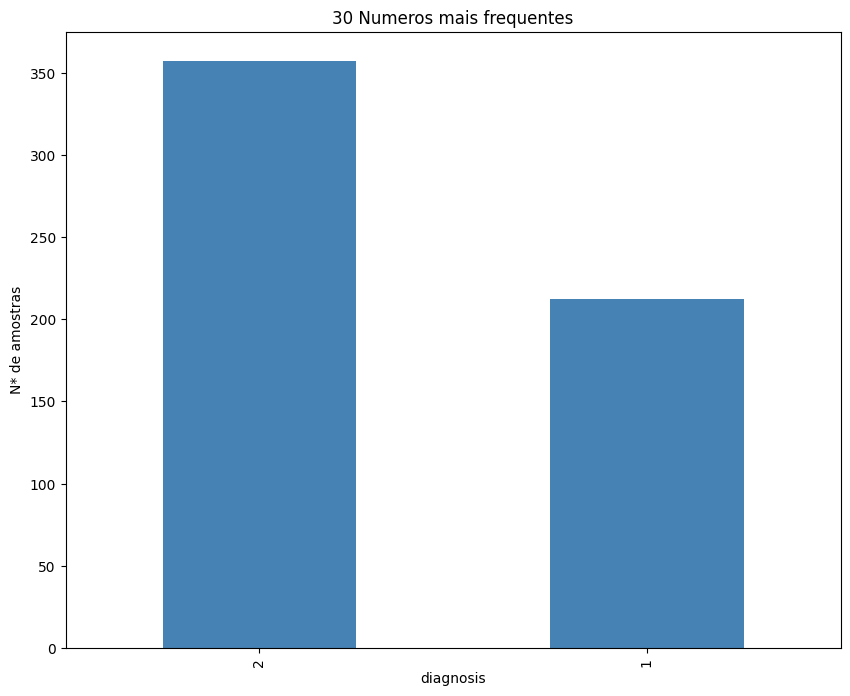

In [ ]:
cont = df6['diagnosis'].value_counts()

print(cont.describe())

#Grafico de 30 valores que mais aparecem de minutos

plt.figure(figsize=(10,8));
cont.head(30).plot(kind='bar', color='steelblue')
plt.title("30 Numeros mais frequentes");
plt.ylabel("N* de amostras");
plt.tight_layout;
plt.show()

In [ ]:
df6 = df6.copy()

x = df6.drop("diagnosis", axis=1)
y = df6['diagnosis'].astype(int)

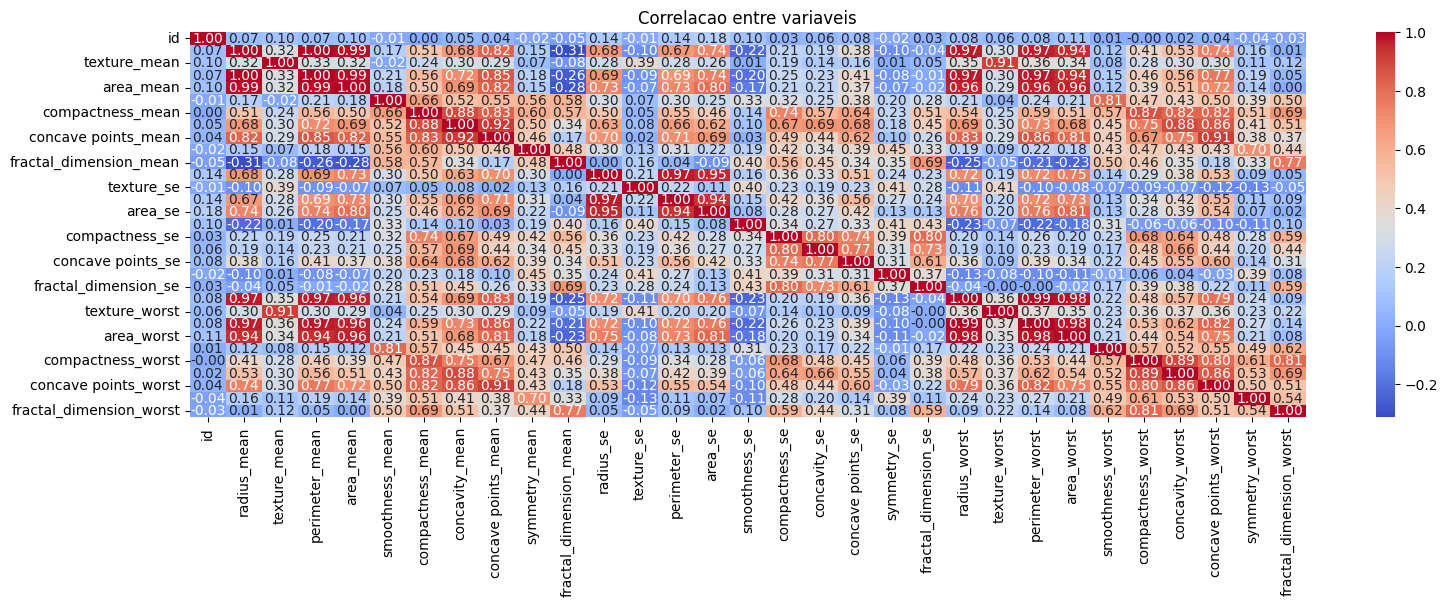

In [ ]:
plt.figure(figsize=(18, 5))
# Seleciona apenas as colunas numéricas
sns.heatmap(x.select_dtypes(include=['number']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlacao entre variaveis")
plt.show()

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)

print("Treino: ", x_train.shape)
print("Teste: ", x_test.shape)

Treino:  (455, 31)
Teste:  (114, 31)


In [ ]:
print(y.value_counts())

diagnosis
2    357
1    212
Name: count, dtype: int64


##4. Treinamento

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Cria uma variável para os modelos já treinados
modelos_treinados = {}

# Loop para treinar cada modelo e adicioná-los aos modelos treinados
for nome, modelo in modelos.items():
  modelo.fit(x_train, y_train)
  modelos_treinados[nome] = modelo
  print(f'Treinamento do modelo {nome} concluído')

Treinamento do modelo Árvore de Decisão concluído
Treinamento do modelo Random Forest concluído
Treinamento do modelo Gradient Boosting concluído


In [ ]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])


#validacao Cruzada com 5 folds

cv = KFold(n_splits=5, shuffle=True, random_state=42)
base = cross_val_score(pipe, x_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)

print("CV 5-fold, SVC-padrao: ", base.round(4))
print("media: ", base.mean())
print("Desvio Padrao: ", base.std())

CV 5-fold, SVC-padrao:  [1.     0.967  0.989  0.978  0.9231]
media:  0.9714285714285715
Desvio Padrao:  0.026556144996911134


GridSearch

In [ ]:
param_grid = {
    'svm__kernel': ['linear', 'rbf', 'poly','sigmoid'],
    'svm__C': [0.1,1,10,100],
    'svm__gamma': [0.001,0.01,0.1,1],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
grid.fit(x_train,y_train)

print("Melhores parametros: ", grid.best_params_)
print("Melhor Acuracia Score na validacao cruzada: ",  grid.best_score_)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Melhores parametros:  {'svm__C': 0.1, 'svm__gamma': 0.001, 'svm__kernel': 'linear'}
Melhor Acuracia Score na validacao cruzada:  0.9758241758241759


In [ ]:
# tabela com as 10 melhores combinacoes

res = pd.DataFrame(grid.cv_results_)[['param_svm__kernel','param_svm__C','param_svm__gamma','mean_test_score','std_test_score']]
res.sort_values('mean_test_score', ascending=False).head(10)

,param_svm__kernel,param_svm__C,param_svm__gamma,mean_test_score,std_test_score
0,linear,0.1,0.001,0.975824,0.018906
4,linear,0.1,0.010,0.975824,0.018906
12,linear,0.1,1.000,0.975824,0.018906
8,linear,0.1,0.100,0.975824,0.018906
51,sigmoid,100.0,0.001,0.975824,0.018906
33,rbf,10.0,0.001,0.973626,0.025631
35,sigmoid,10.0,0.001,0.973626,0.025631
49,rbf,100.0,0.001,0.971429,0.016447
21,rbf,1.0,0.010,0.969231,0.023466
23,sigmoid,1.0,0.010,0.969231,0.027274


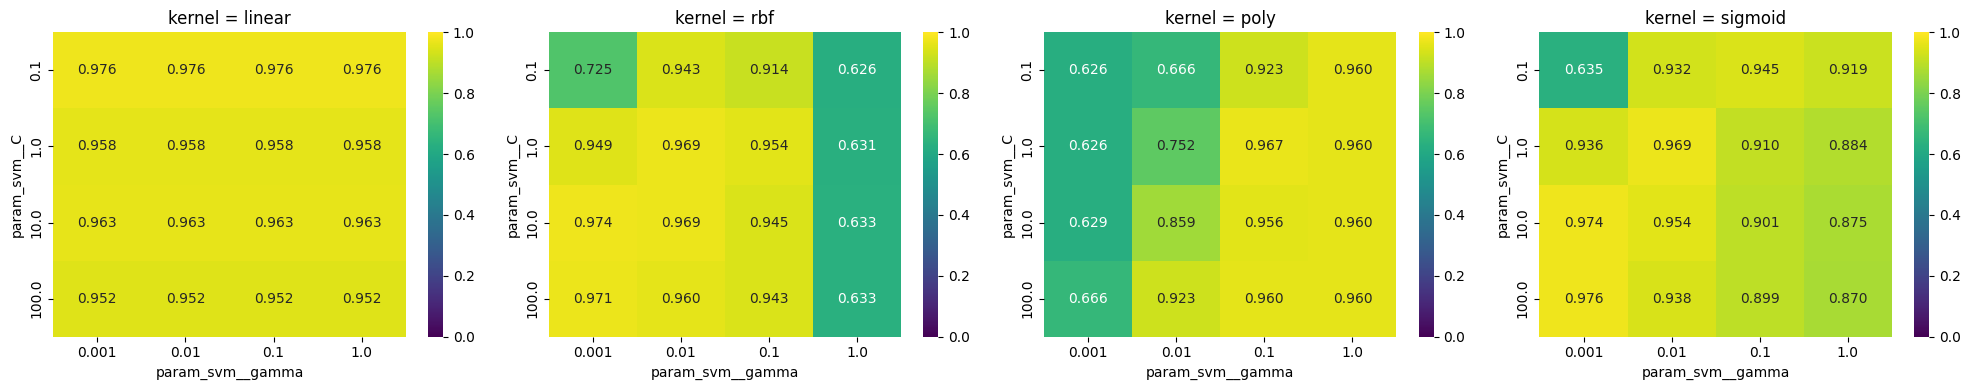

In [ ]:
#um heatmap por kernel pra comparar C x gamma
fig, axes = plt.subplots(1,4, figsize=(20,4))
for ax, k in zip(axes, param_grid['svm__kernel']):
  t = res[res.param_svm__kernel==k].pivot_table(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')
  sns.heatmap(t, annot=True, fmt='.3f', cmap='viridis', ax=ax, vmin=0, vmax=1);
  ax.set_title(f'kernel = {k}')

plt.tight_layout();
plt.show()

In [ ]:
previsoes = {nome: modelo.predict(x_test) for nome, modelo in modelos_treinados.items()}

for nome, y_pred in previsoes.items():
  print(f'{nome} -- {y_pred}')

Árvore de Decisão -- [1 2 1 2 1 2 2 1 1 1 2 1 2 1 1 2 2 2 2 2 1 1 2 2 2 1 1 2 2 2 2 2 2 1 1 1 2
 1 2 1 2 2 2 1 1 1 2 2 1 1 2 2 2 2 2 2 2 1 1 2 2 2 2 2 1 2 1 2 2 2 1 2 2 1
 1 1 1 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 1 1 1 2 1 2 1 1 1 1 1 2 1 1 2 1 2 1 1
 1 2 2]
Random Forest -- [1 2 1 1 1 2 2 1 1 1 2 1 2 1 1 2 2 2 2 2 1 1 2 2 2 1 1 2 2 2 2 2 2 2 1 2 2
 2 2 1 2 2 2 1 1 2 2 2 2 1 2 2 2 2 2 2 2 1 1 2 2 2 2 2 1 2 2 2 2 2 2 2 2 1
 1 1 1 2 2 2 2 2 1 2 1 2 2 2 2 2 2 2 1 1 1 2 1 2 1 2 1 1 1 2 1 1 2 1 2 1 2
 1 2 2]
Gradient Boosting -- [1 2 1 1 1 2 2 1 1 1 2 1 2 1 1 2 2 2 2 2 1 1 2 2 2 2 1 2 2 2 2 2 2 2 1 2 2
 2 2 1 2 2 2 1 1 2 2 2 2 1 2 2 2 2 2 2 2 1 1 2 2 2 2 2 1 2 2 2 2 2 2 2 2 1
 1 1 1 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 1 1 1 2 1 2 1 2 1 1 1 2 1 1 2 1 2 1 2
 1 2 2]


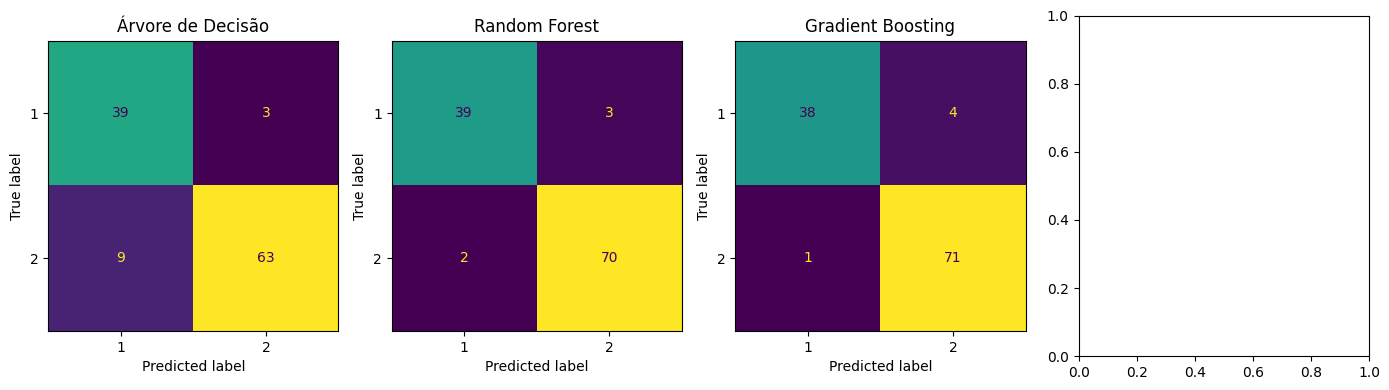

In [ ]:
# Cria as matrizes de confusão dos resultados das predições dos modelos
fig, axes = plt.subplots(1,4, figsize=(14,4))

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
  ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=y.unique(), ax=ax, colorbar=False)
  ax.set_title(nome)

plt.tight_layout()
plt.show()

##5. Teste

In [ ]:
modelo = grid.best_estimator_
y_pred = modelo.predict(x_test)

print('Modelo: ', modelo.named_steps['svm'])
print('Acuracia no teste: %.4f' % accuracy_score(y_test, y_pred))

# precisao, recall e f1
print(classification_report(y_test,y_pred, zero_division=0))

Modelo:  SVC(C=0.1, gamma=0.001, kernel='linear')
Acuracia no teste: 0.9737
              precision    recall  f1-score   support

           1       0.95      0.98      0.96        42
           2       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



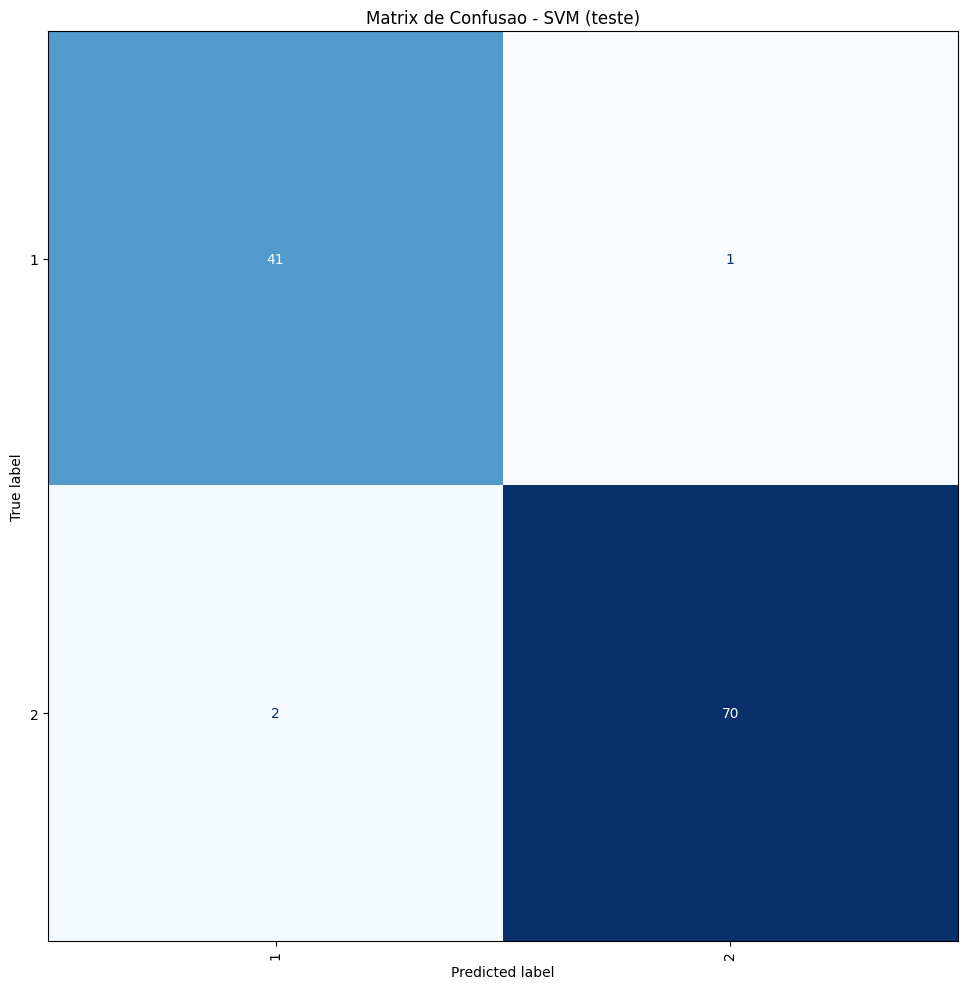

In [ ]:
#matrix de confusao

fig, ax = plt.subplots(figsize=(12,10))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=modelo.classes_), display_labels=modelo.classes_).plot(ax=ax, xticks_rotation=90, cmap='Blues', colorbar=False)
plt.title("Matrix de Confusao - SVM (teste)")
plt.tight_layout()
plt.show()

##6. Avaliação e Comparação

In [ ]:
resultados = []

# Realiza um teste de acurácia e gera um relatório de classificação com cada modelo treinado
for nome, y_pred in previsoes.items():
  acuracia = accuracy_score(y_test, y_pred)
  resultados.append({'Modelo': nome, 'Acurácia': acuracia})
  print(f'{nome} -- Acurácia: {acuracia:.2f}')
  print(classification_report(y_test, y_pred))

Árvore de Decisão -- Acurácia: 0.89
              precision    recall  f1-score   support

           1       0.81      0.93      0.87        42
           2       0.95      0.88      0.91        72

    accuracy                           0.89       114
   macro avg       0.88      0.90      0.89       114
weighted avg       0.90      0.89      0.90       114

Random Forest -- Acurácia: 0.96
              precision    recall  f1-score   support

           1       0.95      0.93      0.94        42
           2       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Gradient Boosting -- Acurácia: 0.96
              precision    recall  f1-score   support

           1       0.97      0.90      0.94        42
           2       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96 

In [ ]:
print('-------- Resumo --------')
print('Modelo : SVC ')
print('Kernel : ', grid.best_params_['svm__kernel'])
print('C : ', grid.best_params_['svm__C'])
print('gamma : ', grid.best_params_['svm__gamma'])
print('Acuracia CV : %.4f' % grid.best_score_)
print("Acuracia no teste : %.4f" % accuracy_score(y_test, y_pred))

-------- Resumo --------
Modelo : SVC 
Kernel :  linear
C :  0.1
gamma :  0.001
Acuracia CV : 0.9758
Acuracia no teste : 0.9561
